# Was he recognised? The PFA Team of the Year model

The same model as the David Silva and Yaya Touré reports: a logistic regression that predicts PFA Team of the Year
selection for midfielders from six per-90 numbers (as percentiles within each season) plus minutes, 2010/11 to
2019/20. Each season is predicted by a model trained on the other nine. Expected selections = the sum of a player's
predicted chances.

Charts 10 and 11 of the report: what the voters reward, and Eriksen's chance of selection each season next to the
midfielders who were picked.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
EXT = ROOT / "data" / "external"
DARK_THEME = os.environ.get("REPORT_THEME") == "dark"  # dark = black-background charts for the PDF; the README uses the light ones
FIGS = ROOT / "reports" / ("figures_dark" if DARK_THEME else "figures")
FIGS.mkdir(parents=True, exist_ok=True)

# Spurs navy for Eriksen, a lighter navy for secondary series
SKY, NAVY, GREY, DARK, MUTED, LIGHT, GOLD = "#7A8BB8", "#132257", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE", "#C9A227"
BG, GRID, SPAN, HEAT, HEAT_HI = "white", "#ECEAE4", "#FBF3DC", [NAVY, SKY, "#E8F1FA", "#FFFFFF"], "white"
if DARK_THEME:  # Spurs navy page: Eriksen in white, others in muted navy
    SKY, NAVY, GREY, DARK, MUTED = "#8C9CC8", "#FFFFFF", "#4A5888", "#FFFFFF", "#B8C0D9"
    BG, GRID, SPAN, HEAT, HEAT_HI = "#132257", "#25356F", "#2A2F5A", ["#FFFFFF", "#8C9CC8", "#2A3B78", "#0D1840"], "#000000"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com. Midfielders as listed in each club's squad, 2010/11 to 2019/20"
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Anton (headlines) and Lato (text), bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Lato", "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": DARK, "legend.labelcolor": DARK,
})


def fs(light, pdf):
    """Figure size: the README (light) size, or a narrower one for the PDF so the text prints larger on the page."""
    return pdf if DARK_THEME else light


def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=18, color=DARK, family="Anton")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)


def season_label(s):
    """2011 -> '2011/12'"""
    return f"{s}/{str(s + 1)[-2:]}"


def load_opta(min_minutes=0):
    """Every Premier League midfielder, 2010/11 to 2019/20 (official Opta stats). Season = starting year."""
    d = pd.concat([pd.read_csv(EXT / "pl_midfielders_2010-2018.csv"), pd.read_csv(EXT / "pl_midfielders_2018-2020.csv")])
    d = d.drop_duplicates(["season", "id"])
    d = d[d.timePlayed >= min_minutes].copy()
    p90 = lambda s: s / d.timePlayed * 90
    d["npg"] = d.goals - d.penaltyGoals
    d["scoring"] = p90(d.npg)                                   # non-penalty goals per 90
    d["assisting"] = p90(d.goalAssists)                         # assists per 90
    d["creating"] = p90(d.keyPassesAttemptAssists)              # chances created per 90
    d["passing"] = p90(d.successfulPassesOppositionHalf)        # completed passes in the opposition half per 90
    d["carrying"] = p90(d.successfulDribbles)                   # successful dribbles per 90
    d["defending"] = p90(d.tacklesWon + d.interceptions)        # tackles won + interceptions per 90
    d["through"] = p90(d.throughBalls)                          # through balls per 90
    d["box"] = p90(d.totalTouchesInOppositionBox)               # touches in the opposition box per 90
    d["dribbles"] = d.successfulDribbles + d.unsuccessfulDribbles
    d["dribble_pct"] = d.successfulDribbles / d.dribbles.where(d.dribbles > 0)
    return d


DIMS = ["scoring", "assisting", "creating", "passing", "carrying", "defending"]
DIM_LABELS = {"scoring": "Scoring\n(non-penalty goals)", "assisting": "Assisting\n(assists)", "creating": "Creating\n(chances created)",
              "passing": "Passing\n(passes in opp. half)", "carrying": "Carrying\n(successful dribbles)",
              "defending": "Defending\n(tackles won + interceptions)"}
ERIKSEN, SILVA = "Christian Eriksen", "David Silva"
SPURS = range(2013, 2019)   # his six full Spurs seasons, 2013/14 to 2018/19 (he left in January 2020)
FINISH = {2013: "6th", 2014: "5th", 2015: "3rd", 2016: "2nd", 2017: "3rd", 2018: "4th", 2019: "6th"}  # Spurs league finish

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict

M = load_opta(min_minutes=1800)
for c in DIMS:
    M["p_" + c] = M.groupby("season")[c].rank(pct=True)
M["p_minutes"] = M.groupby("season").timePlayed.rank(pct=True)
T = pd.read_csv(EXT / "pfa_team_of_the_year.csv")
T["start"] = T.season.str[:4].astype(int)
picked = set(zip(T.start, T.player))
M["toty"] = [(s, n) in picked for s, n in zip(M.season, M.name)]
FEATS = ["p_" + c for c in DIMS] + ["p_minutes"]
M["prob"] = cross_val_predict(LogisticRegression(max_iter=2000), M[FEATS], M.toty, groups=M.season, cv=GroupKFold(10), method="predict_proba")[:, 1]
model = LogisticRegression(max_iter=2000).fit(M[FEATS], M.toty)
COEF = pd.Series(model.coef_[0], index=FEATS)
print(f"{len(M)} seasons, {M.toty.sum()} selections; held-out AUC {roc_auc_score(M.toty, M.prob):.2f}")
COEF.round(2)

757 seasons, 36 selections; held-out AUC 0.87


p_scoring      1.67
p_assisting    1.41
p_creating     0.10
p_passing      1.99
p_carrying     1.71
p_defending    0.24
p_minutes      2.02
dtype: float64

In [3]:
CAREER = M.groupby("name").agg(seasons=("season", "size"), expected=("prob", "sum"), actual=("toty", "sum"))
print(CAREER.loc[ERIKSEN].round(2).to_dict())
M[M.name == ERIKSEN][["season", "prob", "toty"] + FEATS].round(2)

{'seasons': 6.0, 'expected': 1.02, 'actual': 1.0}


,season,prob,toty,p_scoring,p_assisting,p_creating,p_passing,p_carrying,p_defending,p_minutes
779,2013,0.07,False,0.97,0.96,0.96,0.72,0.59,0.13,0.09
971,2014,0.16,False,0.90,0.35,0.93,0.85,0.60,0.16,0.93
1164,2015,0.18,False,0.80,0.95,0.96,0.91,0.49,0.34,0.71
1368,2016,0.23,False,0.89,0.99,0.99,0.84,0.34,0.18,0.95
1543,2017,0.22,True,0.95,0.89,0.96,0.88,0.43,0.24,0.95
157,2018,0.16,False,0.93,0.99,0.88,0.90,0.31,0.14,0.68


In [4]:
# Each season: Eriksen's predicted chance, his rank in that season's prediction, and the midfielders who were picked
SEAS = []
for s in SPURS:
    m = M[M.season == s].sort_values("prob", ascending=False).reset_index(drop=True)
    e = m[m.name == ERIKSEN].iloc[0]
    SEAS.append({"season": s, "prob": e.prob, "rank": int(m.index[m.name == ERIKSEN][0]) + 1, "picked": e.toty,
                 "chosen": ", ".join(m[m.toty].name)})
SEAS = pd.DataFrame(SEAS); SEAS

,season,prob,rank,picked,chosen
0,2013,0.068347,16,False,"Eden Hazard, Yaya Touré, Adam Lallana, Steven ..."
1,2014,0.156386,6,False,"Eden Hazard, Philippe Coutinho, Nemanja Matic"
2,2015,0.183293,4,False,"Dimitri Payet, Riyad Mahrez, Dele Alli, N'Golo..."
3,2016,0.229384,4,False,"Eden Hazard, Dele Alli, Sadio Mané, N'Golo Kanté"
4,2017,0.223336,5,True,"Kevin De Bruyne, David Silva, Christian Eriksen"
5,2018,0.157949,6,False,"Paul Pogba, Bernardo Silva, Fernandinho"


## Charts

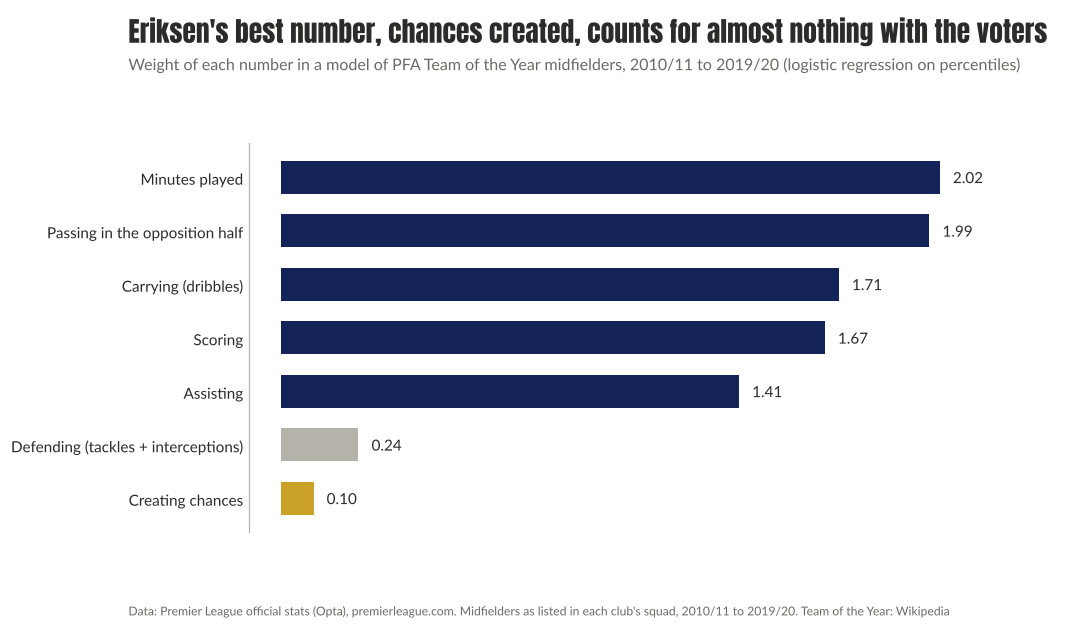

In [5]:
# Figure 10: what the voters reward
lab = {"p_scoring": "Scoring", "p_assisting": "Assisting", "p_creating": "Creating chances", "p_passing": "Passing in the opposition half",
       "p_carrying": "Carrying (dribbles)", "p_defending": "Defending (tackles + interceptions)", "p_minutes": "Minutes played"}
c = COEF.sort_values()
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.barh(range(len(c)), c.values, color=[GOLD if k == "p_creating" else NAVY if v >= 1 else GREY for k, v in c.items()], height=0.62)
for i, v in enumerate(c.values):
    ax.text(max(v, 0) + 0.04, i, f"{v:.2f}", va="center", fontsize=10, color=DARK)
ax.set_yticks(range(len(c)), [lab[k] for k in c.index], fontsize=10)
ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0); ax.set_xlim(min(0, c.min()) - 0.1, c.max() * 1.18)
titles(fig, "Eriksen's best number, chances created, counts for almost nothing with the voters",
       "Weight of each number in a model of PFA Team of the Year midfielders, 2010/11 to 2019/20 (logistic regression on percentiles)",
       SRC_PL + ". Team of the Year: Wikipedia")
fig.savefig(FIGS / "10_what_voters_reward.png")

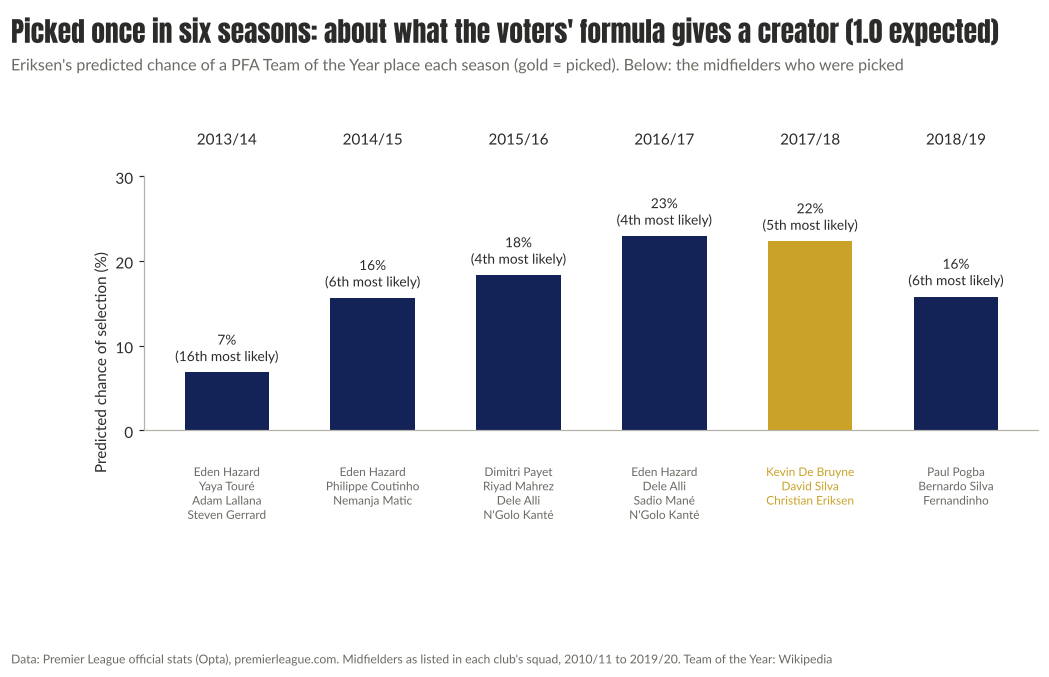

In [6]:
# Figure 11: his chance each season, and who was picked
fig, ax = plt.subplots(figsize=fs((10.5, 5), (9.4, 4.8)))
x = np.arange(len(SEAS))
ax.bar(x, SEAS.prob * 100, color=[GOLD if p else NAVY for p in SEAS.picked], width=0.58)
for xi, r in zip(x, SEAS.itertuples()):
    ax.text(xi, r.prob * 100 + 1, f"{r.prob * 100:.0f}%\n({r.rank}{'st' if r.rank == 1 else 'nd' if r.rank == 2 else 'rd' if r.rank == 3 else 'th'} most likely)",
            ha="center", va="bottom", fontsize=9, color=DARK)
    ax.text(xi, -4, r.chosen.replace(", ", "\n"), ha="center", va="top", fontsize=7.8, color=GOLD if r.picked else MUTED)
ax.set_xticks(x, [season_label(s) for s in SEAS.season], fontsize=10); ax.tick_params(axis="x", pad=2, length=0)
ax.xaxis.set_ticks_position("top"); ax.spines["bottom"].set_visible(False); ax.spines["top"].set_visible(False)
ax.set_ylim(-17, 33); ax.set_yticks([0, 10, 20, 30]); ax.spines["left"].set_bounds(0, 30); ax.set_ylabel("Predicted chance of selection (%)")
ax.axhline(0, color=GREY, lw=0.8)
r = CAREER.loc[ERIKSEN]
titles(fig, f"Picked once in six seasons: about what the voters' formula gives a creator ({r.expected:.1f} expected)",
       "Eriksen's predicted chance of a PFA Team of the Year place each season (gold = picked). Below: the midfielders who were picked",
       SRC_PL + ". Team of the Year: Wikipedia")
fig.savefig(FIGS / "11_selection_by_season.png")